# Porosity

Porosity is the fraction of the rock that's pore space. The library estimates it from three logs
that each see it differently: the density log (bulk density falls as porosity rises), the neutron
log (counts hydrogen, which mostly lives in the pore fluid), and the sonic (sound travels slower
through pores). None is right on its own.

Density porosity is usually the backbone. It's accurate when you know the matrix mineral. The
neutron reads too high in shale, because clay-bound water is hydrogen the tool can't tell from
free water. So the number that matters downstream is **effective** porosity (`PHIE`), which is
total porosity minus that clay-bound water; **total** porosity (`PHIT`) keeps it.

## From three logs to effective porosity

Density porosity comes straight from bulk density,

$$\phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_{fl}}$$

with $\rho_{ma}$ the matrix density (2.65 g/cc for sandstone) and $\rho_{fl}$ the fluid density. The
library blends it with the neutron porosity into a total porosity, density-weighted in clean rock
and taking density alone across gas crossover,

$$\phi_T = 0.6\,\phi_D + 0.4\,\phi_N$$

then subtracts the clay-bound water to give the effective porosity that saturation and net pay use,

$$\phi_E = \phi_T - V_{cl}\,\phi_{cl}$$

where $\phi_{cl}$ is the porosity held in clay (0.15 v/v by default).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "src" / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
WELL = REPO / "src" / "petrophys" / "datasets" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
from petrophys.interpretation.clay_volume import calculate_vcl
from petrophys.interpretation.porosity import calculate_porosity
well = read_las(WELL)
vcl = calculate_vcl(well)
poro = calculate_porosity(well, matrix="sandstone", vcl=vcl.vcl)
print("median PHIT:", round(float(__import__('numpy').nanmedian(poro.phit)), 3),
      "| median PHIE:", round(float(__import__('numpy').nanmedian(poro.phie)), 3))

median PHIT: 0.392 | median PHIE: 0.372


`PHIE` sits below `PHIT` by the clay-bound water, and the gap widens with clay content: in a
clean sand they're nearly equal, in a shale they diverge. Seen against depth alongside clay
volume, the relationship is clear:

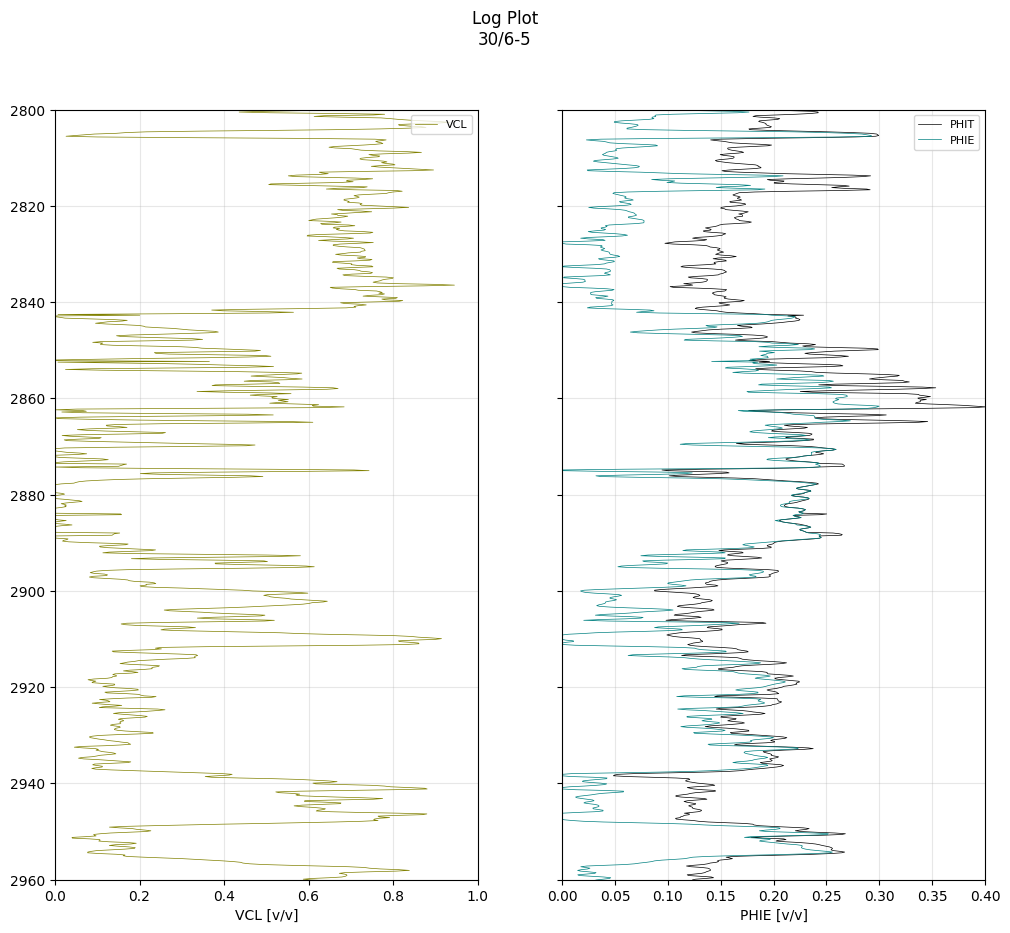

In [2]:
from petrophys.interpretation.porosity import PorosityModule
from petrophys.interpretation.clay_volume.vcl_module import VclModule
from petrophys.visualization import create_log_plot
VclModule(matrix="sandstone", combine="auto").add_to_well(well)
PorosityModule(matrix="sandstone").add_to_well(well)   # writes PHID, PHIT, PHIE, ...
create_log_plot(well, depth_range=(2800, 2960), curves=[
    {"track": 0, "name": "VCL", "color": "olive", "xlim": (0, 1)},
    {"track": 1, "name": "PHIT", "color": "black", "xlim": (0, 0.4)},
    {"track": 1, "name": "PHIE", "color": "teal", "xlim": (0, 0.4)},
]);

Use `PHIE` for saturation and net pay. It's the porosity that can actually hold and flow
hydrocarbons. The *core calibration* deep dive checks both against 200 core plugs in this well;
total porosity matches the core, and effective sits just below it, exactly as it should.